## First method

In [1]:
import pandas as pd
from spacepy import pycdf
import numpy as np
from scipy.linalg import eig
import matplotlib.pyplot as plt

# Load the CDF file
cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
cdf = pycdf.CDF(cdf_path)
cdf

<CDF:
Epoch: CDF_TIME_TT2000 [1051008]
Epoch_state: CDF_TIME_TT2000 [2883]
label_b_bcs: CDF_CHAR*10 [4] NRV
label_b_dmpa: CDF_CHAR*10 [4] NRV
label_b_gse: CDF_CHAR*10 [4] NRV
label_b_gsm: CDF_CHAR*11 [4] NRV
label_r_gse: CDF_CHAR*10 [4] NRV
label_r_gsm: CDF_CHAR*10 [4] NRV
mms1_fgm_b_bcs_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_dmpa_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gse_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gsm_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_bdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_etemp_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_flag_srvy_l2: CDF_UINT4 [1051008]
mms1_fgm_hirange_srvy_l2: CDF_UINT1 [1051008]
mms1_fgm_mode_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_r_gse_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_r_gsm_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_rdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_stemp_srvy_l2: CDF_FLOAT [1051008]
represent_vec_tot: CDF_CHAR*1 [4] NRV
>

In [2]:

# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
B_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
B_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
B_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]
B_T = cdf['mms1_fgm_b_gse_srvy_l2'][:,3]
# Combine and interpolate the data
data = pd.DataFrame({
    'datetime': datetime,
    'B_x': B_x,
    'B_y': B_y,
    'B_z': B_z
}).set_index('datetime').interpolate()

# Select data within the specified time range
start_time = pd.Timestamp('2015-10-28 16:45:05')
end_time = pd.Timestamp('2015-10-28 16:45:08')
data = data.loc[start_time:end_time]

# Calculate mean values
m1, m2, m3 = data.mean()

# Calculate covariance matrix components
M11 = (data['B_x'] * data['B_x']).mean() - m1**2
M12 = (data['B_x'] * data['B_y']).mean() - m1*m2
M13 = (data['B_x'] * data['B_z']).mean() - m1*m3
M21 = M12
M22 = (data['B_y'] * data['B_y']).mean() - m2**2
M23 = (data['B_y'] * data['B_z']).mean() - m2*m3
M31 = M13
M32 = M23
M33 = (data['B_z'] * data['B_z']).mean() - m3**2

# Create the covariance matrix
M = np.array([[M11, M12, M13],
              [M21, M22, M23],
              [M31, M32, M33]])

# Calculate eigenvalues and eigenvectors
vals, vecs = eig(M)
vals = np.real(vals)
vecs = np.real(vecs)

# Sort eigenvalues and corresponding eigenvectors
sorted_indices = np.argsort(vals)[::-1]
eig_vals = vals[sorted_indices]
eig_vecs = vecs[:, sorted_indices]

# Correct eigenvector orientations
X = np.cross(eig_vecs[:, 0], eig_vecs[:, 1])
Y = eig_vecs[:, 2]
if not np.array_equal(X, Y):
    eig_vecs[:, 1] *= -1
    eig_vecs[:, 2] *= -1

# Perform MVA
mva_matrix = np.dot(data[['B_x', 'B_y', 'B_z']], eig_vecs)
a=data['B_L'] = mva_matrix[:, 0]
b=data['B_M'] = mva_matrix[:, 1]
c=data['B_N'] = mva_matrix[:, 2]
B_tot = np.sqrt(a**2+b**2+c**2)

mva_matrix



array([[ -2.4333987, -12.759504 ,  46.4642   ],
       [ -2.2706337, -12.801839 ,  46.48636  ],
       [ -2.1239846, -12.826121 ,  46.512814 ],
       [ -2.0056658, -12.841317 ,  46.518044 ],
       [ -1.9365526, -12.869733 ,  46.53167  ],
       [ -1.8996664, -12.907545 ,  46.541515 ],
       [ -1.9299563, -12.962115 ,  46.543297 ],
       [ -1.9723107, -13.000751 ,  46.539085 ],
       [ -2.0551422, -13.032142 ,  46.56024  ],
       [ -2.2017648, -13.077244 ,  46.55214  ],
       [ -2.3414028, -13.096904 ,  46.524757 ],
       [ -2.5226867, -13.09151  ,  46.53267  ],
       [ -2.6915274, -13.096196 ,  46.527996 ],
       [ -2.8473713, -13.102323 ,  46.510117 ],
       [ -2.9804888, -13.095449 ,  46.51072  ],
       [ -3.0708148, -13.042025 ,  46.521828 ],
       [ -3.1348934, -12.996826 ,  46.533478 ],
       [ -3.1515946, -12.942942 ,  46.5321   ],
       [ -3.149272 , -12.892202 ,  46.53122  ],
       [ -3.0950074, -12.831823 ,  46.533722 ],
       [ -2.9991837, -12.794901 ,  46.55

In [3]:
data

,B_x,B_y,B_z,B_L,B_M,B_N
datetime,,,,,,
2015-10-28 16:45:05.010090,14.571877,13.215993,44.052765,-2.433399,-12.759504,46.464199
2015-10-28 16:45:05.135091,14.419348,13.229939,44.125679,-2.270634,-12.801839,46.486359
2015-10-28 16:45:05.260093,14.286210,13.228879,44.196873,-2.123985,-12.826121,46.512814
2015-10-28 16:45:05.385095,14.174523,13.223615,44.238777,-2.005666,-12.841317,46.518044
2015-10-28 16:45:05.510096,14.109347,13.239842,44.274254,-1.936553,-12.869733,46.531670
2015-10-28 16:45:05.635098,14.071638,13.270827,44.296730,-1.899666,-12.907545,46.541515
2015-10-28 16:45:05.760100,14.091589,13.329787,44.291798,-1.929956,-12.962115,46.543297
2015-10-28 16:45:05.885101,14.123603,13.375083,44.276711,-1.972311,-13.000751,46.539085
2015-10-28 16:45:06.010103,14.202571,13.420299,44.273006,-2.055142,-13.032142,46.560242


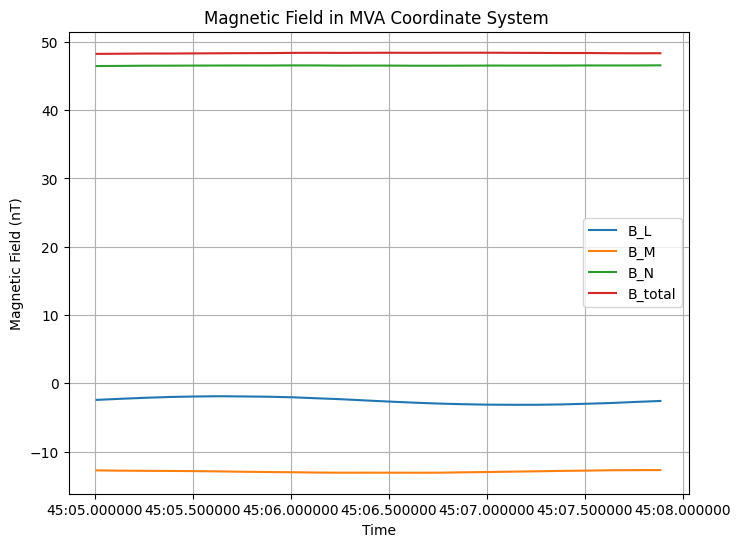

In [4]:
# Correct eigenvector orientations
X = np.cross(eig_vecs[:, 0], eig_vecs[:, 1])
Y = eig_vecs[:, 2]
if not np.allclose(X, Y, atol=1e-8):
    eig_vecs[:, 1] *= -1
    eig_vecs[:, 2] *= -1

# Perform MVA
mva_matrix = np.dot(data[['B_x', 'B_y', 'B_z']], eig_vecs)
data['B_L'] = mva_matrix[:, 0]
data['B_M'] = mva_matrix[:, 1]
data['B_N'] = mva_matrix[:, 2]

# Plot the results
plt.figure(figsize= (8,6))
plt.plot(data.index, a, label='B_L')
plt.plot(data.index, b, label='B_M')
plt.plot(data.index, c, label='B_N')
plt.plot(data.index, B_tot, label = 'B_total')
plt.xlabel('Time')
plt.ylabel('Magnetic Field (nT)')
plt.title('Magnetic Field in MVA Coordinate System ')
plt.legend()
plt.grid()
plt.show()


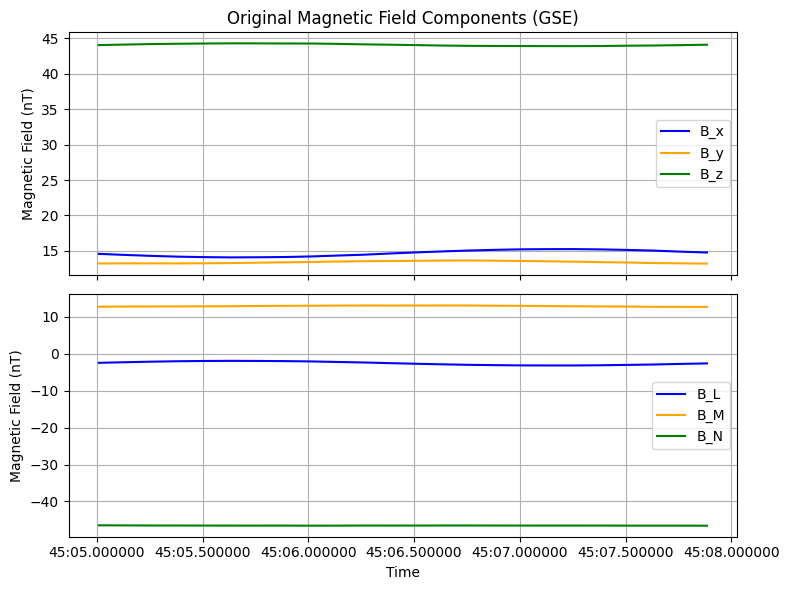

In [5]:
# Plot the results with subplots
fig, axs = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# First subplot: Original magnetic field components
axs[0].plot(data.index, data['B_x'], label='B_x', color='blue')
axs[0].plot(data.index, data['B_y'], label='B_y', color='orange')
axs[0].plot(data.index, data['B_z'], label='B_z', color='green')
axs[0].set_ylabel('Magnetic Field (nT)')
axs[0].set_title('Original Magnetic Field Components (GSE)')
axs[0].legend()
axs[0].grid()

# Second subplot: MVA magnetic field components
axs[1].plot(data.index, data['B_L'], label='B_L', color='blue')
axs[1].plot(data.index, data['B_M'], label='B_M', color='orange')
axs[1].plot(data.index, data['B_N'], label='B_N', color='green')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Magnetic Field (nT)')
# axs[1].set_title('Magnetic Field Components in MVA Coordinate System')
axs[1].legend()
axs[1].grid()

# Adjust layout
plt.tight_layout()
plt.show()


In [6]:
m1

14.667346000671387

In [7]:
m2 

13.399556159973145

In [8]:
m3

44.09034729003906

In [9]:
eig_vecs

array([[-0.9365295 , -0.1643254 , -0.3096931 ],
       [-0.17124254,  0.9852166 , -0.00491605],
       [ 0.30592254,  0.04842869, -0.95082384]], dtype=float32)

In [10]:
M

array([[ 0.17494202,  0.02906799, -0.0569458 ],
       [ 0.02906799,  0.02276611, -0.00958252],
       [-0.0569458 , -0.00958252,  0.01916504]], dtype=float32)

In [11]:
mva_matrix

array([[ -2.4333987,  12.759504 , -46.4642   ],
       [ -2.2706337,  12.801839 , -46.48636  ],
       [ -2.1239846,  12.826121 , -46.512814 ],
       [ -2.0056658,  12.841317 , -46.518044 ],
       [ -1.9365526,  12.869733 , -46.53167  ],
       [ -1.8996664,  12.907545 , -46.541515 ],
       [ -1.9299563,  12.962115 , -46.543297 ],
       [ -1.9723107,  13.000751 , -46.539085 ],
       [ -2.0551422,  13.032142 , -46.56024  ],
       [ -2.2017648,  13.077244 , -46.55214  ],
       [ -2.3414028,  13.096904 , -46.524757 ],
       [ -2.5226867,  13.09151  , -46.53267  ],
       [ -2.6915274,  13.096196 , -46.527996 ],
       [ -2.8473713,  13.102323 , -46.510117 ],
       [ -2.9804888,  13.095449 , -46.51072  ],
       [ -3.0708148,  13.042025 , -46.521828 ],
       [ -3.1348934,  12.996826 , -46.533478 ],
       [ -3.1515946,  12.942942 , -46.5321   ],
       [ -3.149272 ,  12.892202 , -46.53122  ],
       [ -3.0950074,  12.831823 , -46.533722 ],
       [ -2.9991837,  12.794901 , -46.55

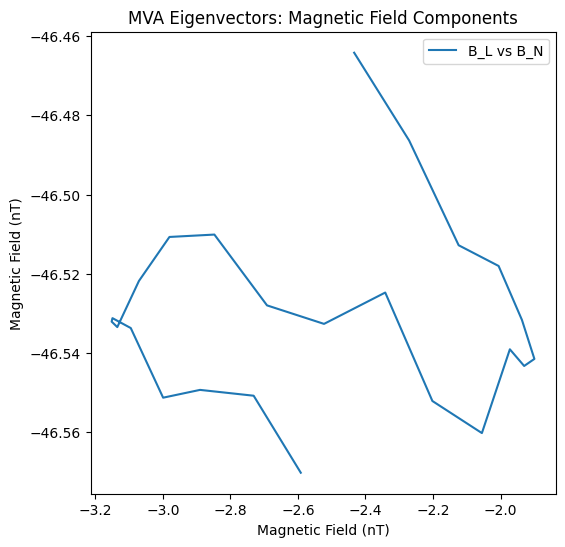

In [12]:
# Plot results
plt.figure(figsize=(6, 6))
plt.plot(data['B_L'], data['B_N'], label='B_L vs B_N')
plt.xlabel('Magnetic Field (nT)')
plt.ylabel('Magnetic Field (nT)')
plt.legend()
plt.title('MVA Eigenvectors: Magnetic Field Components')
plt.show()


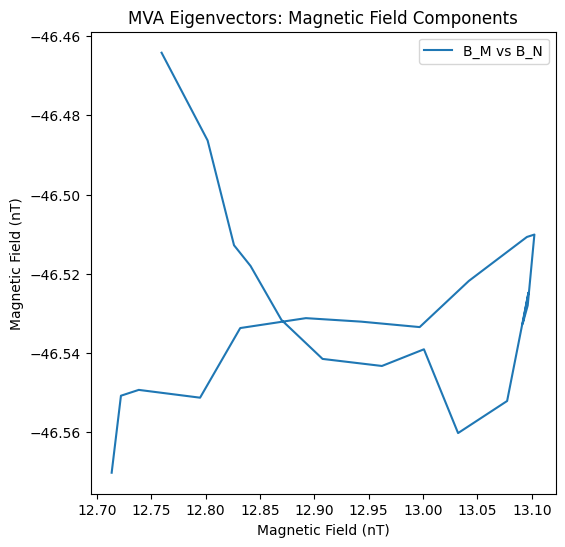

In [13]:
# Plot results
plt.figure(figsize=(6, 6))
plt.plot(data['B_M'], data['B_N'], label='B_M vs B_N')
plt.xlabel('Magnetic Field (nT)')
plt.ylabel('Magnetic Field (nT)')
plt.legend()
plt.title('MVA Eigenvectors: Magnetic Field Components')
plt.show()


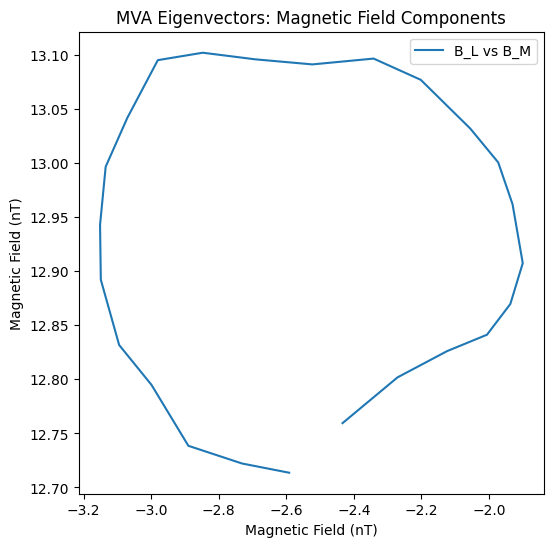

In [14]:
plt.figure(figsize=(6, 6))
plt.plot(data['B_L'], data['B_M'], label='B_L vs B_M')
plt.xlabel('Magnetic Field (nT)')
plt.ylabel('Magnetic Field (nT)')
plt.legend()
plt.title('MVA Eigenvectors: Magnetic Field Components')
plt.show()


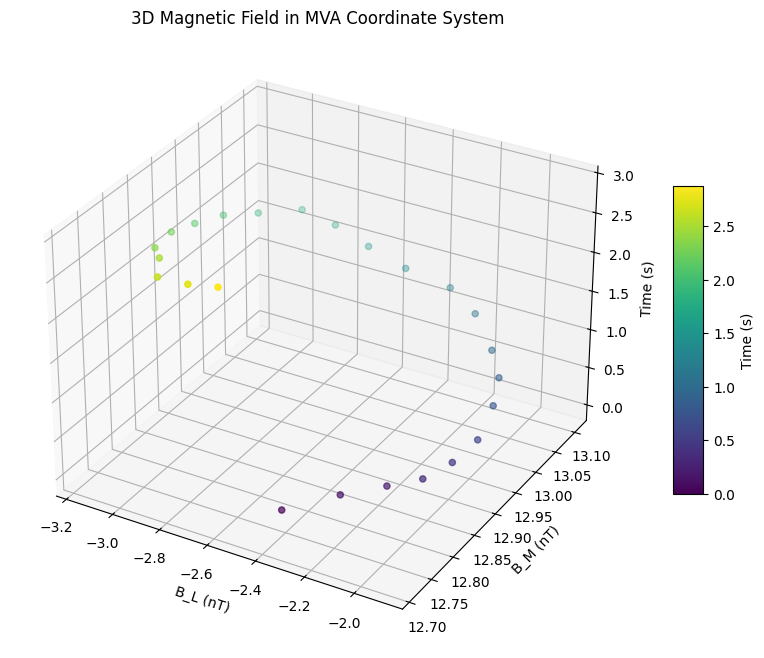

In [15]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

# Create a 3D figure
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Convert time to seconds relative to the start of the range
time = (data.index - data.index[0]).total_seconds()

# Extract data for plotting
x = data['B_L']
y = data['B_M']
z = time

# Create a scatter plot with color representing time
sc = ax.scatter3D(x, y, z, c=z, cmap='viridis', label='B_L vs B_M vs Time')

# Add labels and title
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_M (nT)')
ax.set_zlabel('Time (s)')
ax.set_title('3D Magnetic Field in MVA Coordinate System')

# Add a color bar
cbar = plt.colorbar(sc, ax=ax, shrink=0.5, aspect=10)
cbar.set_label('Time (s)')

# Show the plot
plt.show()


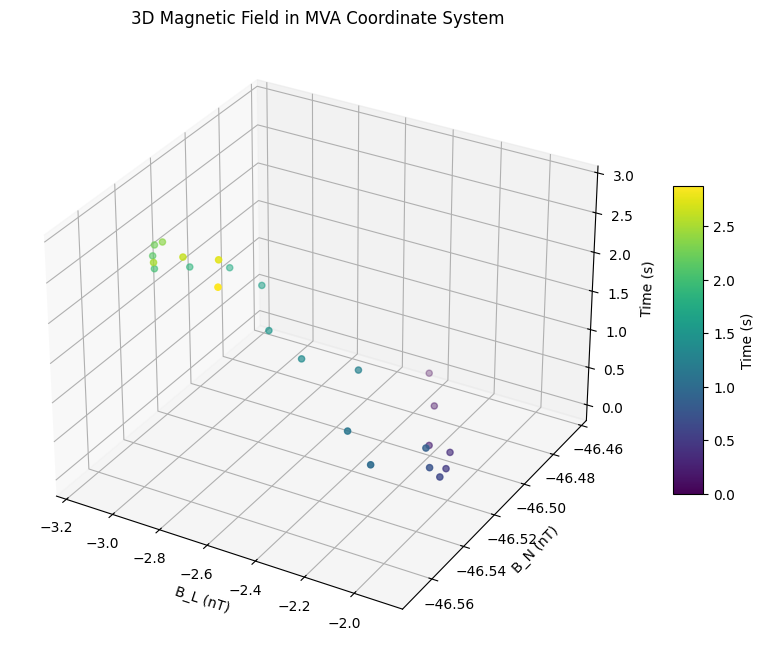

In [16]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

# Create a 3D figure
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Convert time to seconds relative to the start of the range
time = (data.index - data.index[0]).total_seconds()

# Extract data for plotting
x = data['B_L']
y = data['B_N']
z = time

# Create a scatter plot with color representing time
sc = ax.scatter3D(x, y, z, c=z, cmap='viridis', label='B_L vs B_M vs Time')

# Add labels and title
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_N (nT)')
ax.set_zlabel('Time (s)')
ax.set_title('3D Magnetic Field in MVA Coordinate System')

# Add a color bar
cbar = plt.colorbar(sc, ax=ax, shrink=0.5, aspect=10)
cbar.set_label('Time (s)')

# Show the plot
plt.show()


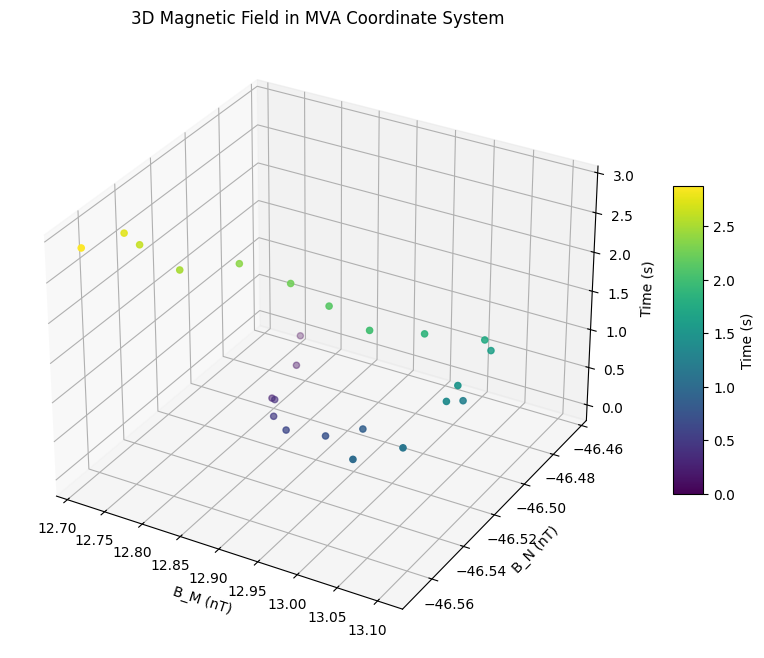

In [17]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

# Create a 3D figure
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Convert time to seconds relative to the start of the range
time = (data.index - data.index[0]).total_seconds()

# Extract data for plotting
x = data['B_M']
y= data['B_N']
z = time

# Create a scatter plot with color representing time
sc = ax.scatter3D(x, y, z, c=z, cmap='viridis', label='B_L vs B_M vs Time')

# Add labels and title
ax.set_xlabel('B_M (nT)')
ax.set_ylabel('B_N (nT)')
ax.set_zlabel('Time (s)')
ax.set_title('3D Magnetic Field in MVA Coordinate System')

# Add a color bar
cbar = plt.colorbar(sc, ax=ax, shrink=0.5, aspect=10)
cbar.set_label('Time (s)')

# Show the plot
plt.show()
